# Graph input for clonal embeddings

`c2v.tl.clonal_nn` finds each cell's nearest neighbours in a **coordinate space**, such as PCA or a batch-corrected PCA. Some methods don't give you coordinates, only a graph:

* **Weighted Nearest Neighbors (WNN)** integrates several modalities into a cell–cell graph;
* **batch-balanced kNN (bbknn)** corrects batch effects by building a balanced cell–cell graph.

**The trick: turn the graph into coordinates.** Laplacian eigenmaps assign every cell a few coordinates such that cells strongly connected in the graph get similar coordinates. Formally, these are the smoothest functions on the graph: the eigenvectors of the graph Laplacian with the smallest eigenvalues. Nearest neighbours in this new space then approximate neighbours in the graph, and `clonal_nn` can use it like any other representation.

We use CD8 T cells from the Liu et al. NSCLC cohort, where clones are defined by T cell receptor sequences. The original study corrected batch effects with bbknn, so we do the same here. (The clone2vec manuscript re-processed this dataset with Harmony instead.)

**The plan:**

1. Build a bbknn graph of the cells.
2. Turn it into coordinates with Laplacian eigenmaps.
3. Build the clonal embedding as usual.
4. Check for batch effects.
5. Find and interpret clonal clusters.

## Setup

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v
import scanpy.external as sce

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

## Step 1: Build a batch-balanced graph of the cells

bbknn finds each cell's neighbours separately within every sample, then merges them. Cells can't connect only to cells of their own sample, which removes sample-specific shifts from the graph.

In [2]:
adata = c2v.datasets.Liu_NSCLC_CD8(embedding_type="gex")

using gene expression embedding


In [3]:
sce.pp.bbknn(adata, use_rep="X_pca", n_pcs=30, batch_key="sample")

computing batch balanced neighbors
	finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:52)


In [4]:
sc.tl.umap(adata, min_dist=0.3)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:05:07)


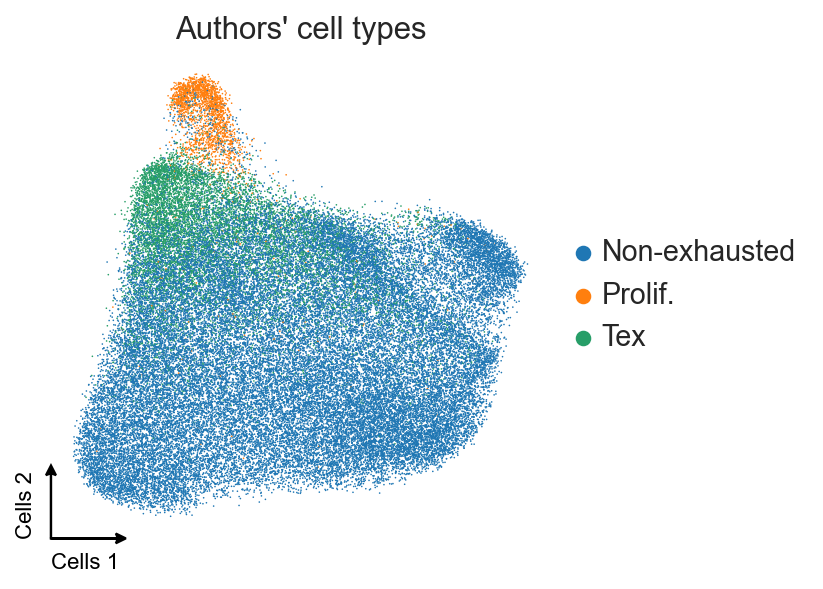

In [5]:
ax = sc.pl.umap(adata, color="cluster", frameon=False,
                title="Authors' cell types", show=False)

c2v.pl.embedding_axis(ax, label="Cells")

The authors' annotation has three broad states: non-exhausted, exhausted (Tex) and proliferating T cells, with gradual transitions between them.

## Step 2: Turn the graph into coordinates

This is the key step. `c2v.utils.laplacian_eigenmaps` takes the graph in `adata.obsp["connectivities"]` and computes 20 Laplacian eigenmap coordinates, stored in `adata.obsm["X_laplacian"]`.

In [6]:
c2v.utils.laplacian_eigenmaps(adata)

computing Laplacian eigenmaps: 
    using .obsp['connectivities'], n_components=20
    finished (0:00:16): added
     .obsm['X_laplacian'] Laplacian eigenmaps (20 components)
     .uns['laplacian_eigenmaps'] parameters


## Step 3: The clonal embedding

**Which unit is a clone?** `adata.obs["full_clone"]` combines the T cell receptor with the biopsy site and time point, so cells sharing a receptor but sampled at different sites or times are treated as separate units. Each unit then describes how the clone behaves in one place at one time.

We keep units with at least 3 cells.

In [7]:
clones = c2v.pp.clones_adata(adata, obs_name="full_clone", min_size=3)

creating clone-level AnnData
    selected 1591 clones (>= 3)
    finished (0:00:01): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label


From here on, everything is standard. The only difference is `use_rep="X_laplacian"`: neighbours are now found in the coordinates derived from the bbknn graph.

In [8]:
c2v.tl.clonal_nn(adata, clones, use_rep="X_laplacian")

computing clone-to-clone adjacency graph
    finished (0:00:38): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


In [9]:
c2v.tl.clone2vec(clones)

fitting clone2vec embeddings
    SG epochs:  13%|█▎        | 63/500 [06:03<42:00,  5.77s/it, loss=5.0829, Δ=4.31e-05]
    early stopping at epoch 64
    finished (0:06:05): added
     .obsm['clone2vec'] embedding matrix
     .uns['clone2vec'] training details


In [10]:
sc.pp.neighbors(clones, use_rep="clone2vec")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)


In [11]:
sc.tl.umap(clones)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


## Step 4: Check for batch effects

T cell receptor clones are patient-specific, so the patient is a natural batch variable. We copy the patient, biopsy site and treatment history from the cells to the clones, then colour the clonal map by patient. In a batch-free embedding, patients should be mixed throughout.

In [12]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_adata=["patient", "biospy_site", "treatment_hx"])

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_patient'] categorical labels
     .obs['gex_biospy_site'] categorical labels
     .obs['gex_treatment_hx'] categorical labels


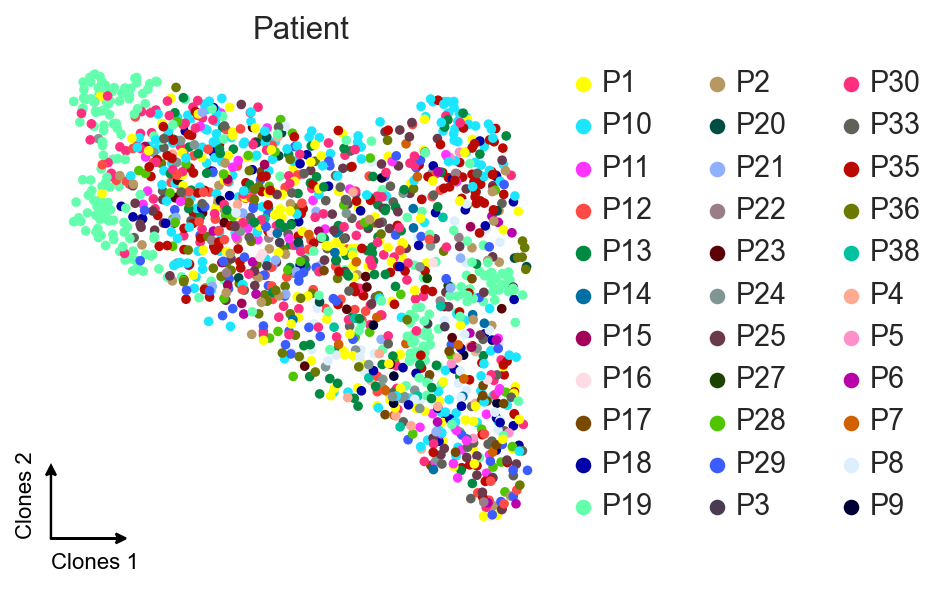

In [14]:
ax = sc.pl.umap(clones, color=["gex_patient"], frameon=False,
                title="Patient", show=False)

c2v.pl.embedding_axis(ax, label="Clones")

**What to look for:** patients are mostly mixed, but the clones of patient P19 (light green) concentrate at the edges. A small batch effect from this patient has propagated into the clonal space. [Batch effects in clonal embeddings](Batch_effect_propagation.ipynb) shows how to diagnose and correct it. For now, we keep going.

## Step 5: Clonal clusters

A low resolution (`0.2`) gives a few broad clonal behaviours.

In [15]:
sc.tl.leiden(clones, resolution=0.2, flavor="igraph", n_iterations=2)

running Leiden clustering
    finished: found 3 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


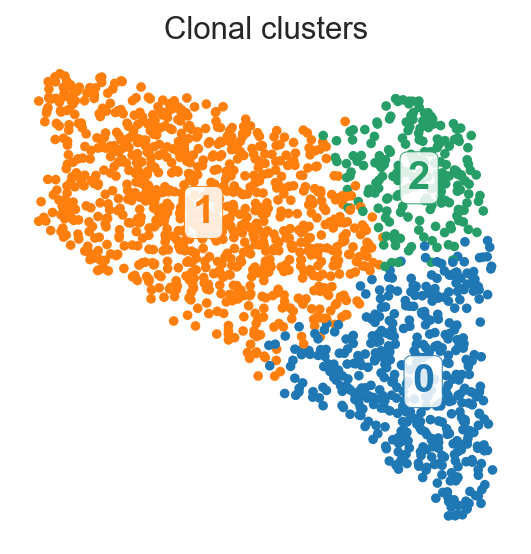

In [16]:
ax = sc.pl.umap(clones, color="leiden", title="Clonal clusters",
                frameon=False, show=False)

c2v.pl.fancy_legend(ax, textsize=18, center_loc=True, fontweight="bold")

To understand what the three clusters are, we look at where their cells sit on the expression map.

In [17]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_clones="leiden")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['c2v_leiden'] categorical labels


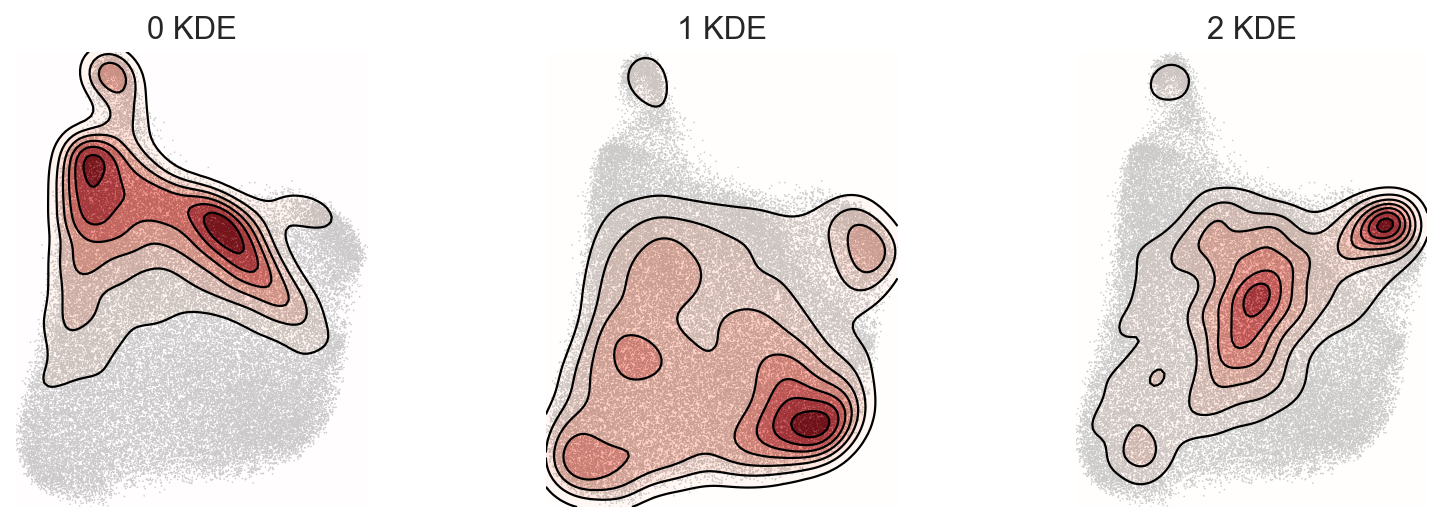

In [18]:
c2v.pl.group_kde(adata, groupby="c2v_leiden", groups=["0", "1", "2"], bw_method=0.2)

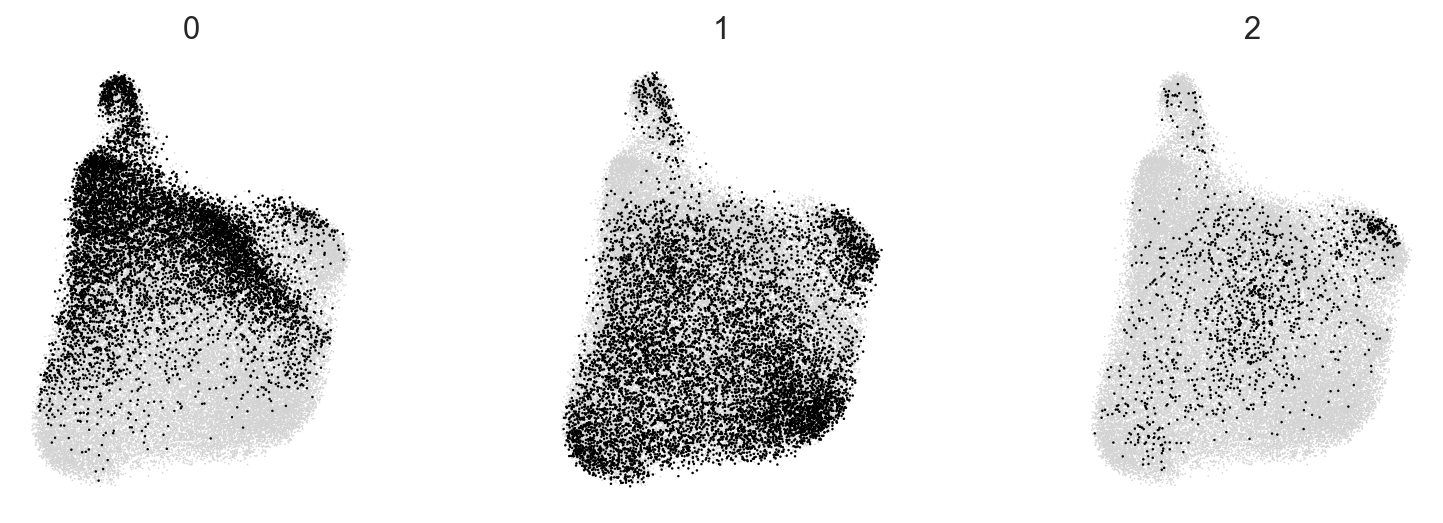

In [19]:
c2v.pl.group_scatter(adata, groupby="c2v_leiden", groups=["0", "1", "2"], s=5)

**What to look for:**

* **Cluster 0** concentrates on the exhausted (Tex) region and the proliferating cells next to it.
* **Cluster 1** spreads over the large non-exhausted region, with most cells in its lower part.
* **Cluster 2** concentrates in the central and right parts of the non-exhausted region.

Clusters 1 and 2 both look "non-exhausted" by annotation, yet their clones occupy different parts of that state. This difference is invisible to cell type labels.

## Step 6: Marker genes

`c2v.pp.transfer_expression` averages the expression of each clone over its cells. Each clone then has an expression profile, and we can plot genes directly on the clonal map.

In [20]:
clones = c2v.pp.transfer_expression(adata, clones)

summarizing expression at clone level: 
    using `adata.X` as expression source
    finished (0:00:07): created clone-level AnnData with
     .X aggregated expression matrix (clones × genes)
     .uns['transfer_expression'] dict with 'strategy'
     .uns['mask_key'] string with obsm key for boolean mask of clones with non-zero cells
     .obsm['proportions'] dataframe of features
     .obsm['counts'] dataframe of features


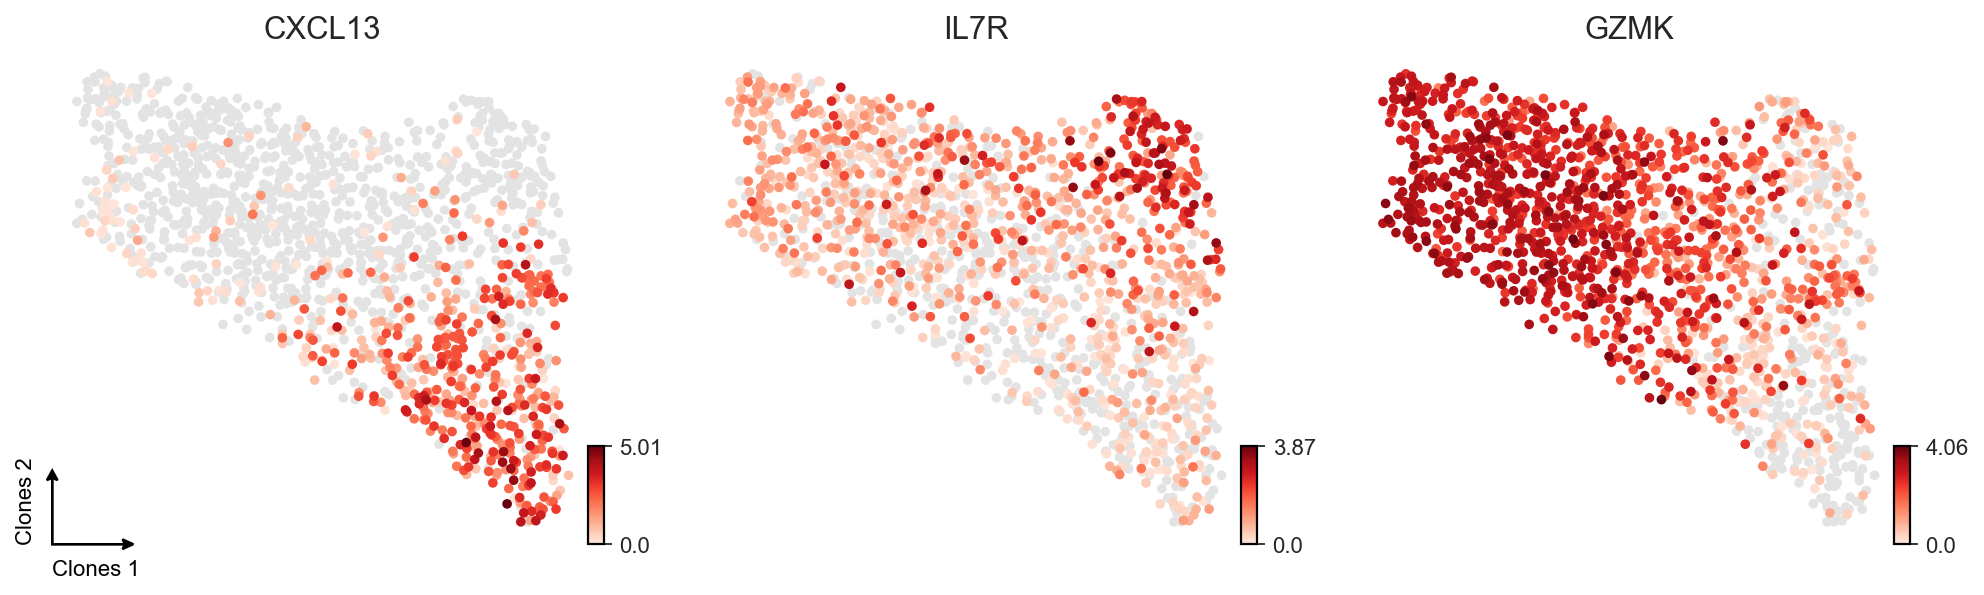

In [21]:
axes = sc.pl.umap(clones, color=["CXCL13", "IL7R", "GZMK"], frameon=False,
                  show=False, cmap=c2v.pl.Reds)
c2v.pl.small_cbar(axes)
c2v.pl.embedding_axis(axes[0], label="Clones")

A scaled dot plot summarizes the same genes per cluster. Colour is the mean z-score across clones; dot size is the fraction of clones expressing the gene.

/home/sergey/miniconda3/envs/sl/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


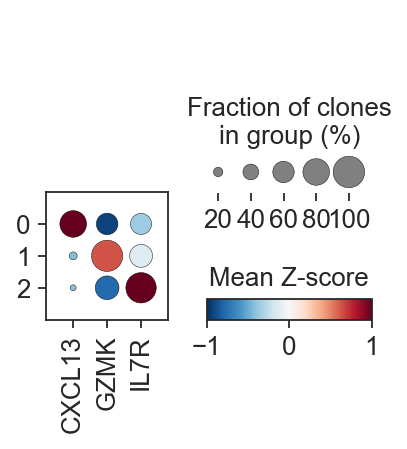

In [23]:
axes = c2v.pl.scaled_dotplot(
    clones,
    groupby="leiden",
    var_names=["CXCL13", "GZMK", "IL7R"],
    vmax=1,
    vmin=-1,
    size_title="Fraction of clones\nin group (%)",
)

**What to look for:** each cluster has its own program:

* **Cluster 0:** CXCL13, a marker of exhausted, tumour-reactive clones;
* **Cluster 1:** GZMK, a marker of effector-memory clones;
* **Cluster 2:** IL7R, a marker of memory-like clones.

These are the same clonal programs reported in the original study and in the clone2vec manuscript, recovered here from a bbknn-based graph. The graph input works as well as a regular embedding.

We save the clonal object for the [batch effect notebook](Batch_effect_propagation.ipynb).

In [24]:
clones.write_h5ad("Liu_CD8_bbknn_c2v.h5ad")